# Session 7 — Demo 3 — What are ten thousand complaints about?

**What this demo covers.** A pile of texts and one question: *what are people writing about?* Nobody labelled them, so this is clustering again, but texts have no coordinates. We turn words into numbers step by step: word counts, then **TF-IDF**, then a small neural network called an **encoder** that places texts with similar meaning close together. We encode 5,000 real bank complaints on a laptop, find duplicates, cluster with k-means, read and name the clusters, and check them against the regulator's official categories, which the model never saw. Then we draw the 384-dimensional result on a flat page three ways (**PCA**, **t-SNE**, **UMAP**) and learn how not to be fooled by the pictures. We try the pipeline in the other order (compress first, then cluster with HDBSCAN), and finish with one month that looks like a trend and isn't.

**Data.** `data/complaints/`: 10,710 real complaints to the US Consumer Financial Protection Bureau (CFPB), public domain, personal details masked by the regulator, plus real monthly complaint counts. See the [data dictionary](../../data/README.md).

**How to run.** Locally: top to bottom. The first run downloads the encoder, about 90 MB. Colab: uncomment the setup lines; `umap-learn` needs installing. If the encoder download fails, the setup of section 3 shows how to load precomputed vectors instead.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

# where the data lives, relative to this notebook
DATA = Path("../../data")

# --- Google Colab? Uncomment these lines to fetch the course repo: ---
# !git clone https://github.com/seemsGoodNow/hse-data-science-course.git course
# DATA = Path("course/data")
# %pip install sentence-transformers umap-learn

CLUSTER_COLORS = [
    "#4a7ebb",
    "#c0392b",
    "#27ae60",
    "#8e44ad",
    "#e67e22",
    "#16a085",
    "#e84393",
    "#2c3e50",
]
NOISE_COLOR = "#d5dbe3"
MAIN_COLOR = "#4a7ebb"

# the regulator's product names are long; short names for tables and charts
PRODUCT_SHORT = {
    "Checking or savings account": "Bank account",
    "Credit card": "Credit card",
    "Debt collection": "Debt collection",
    "Money transfer, virtual currency, or money service": "Money transfer",
    "Mortgage": "Mortgage",
    "Student loan": "Student loan",
    "Vehicle loan or lease": "Car loan",
}

In [2]:
def make_ax_better(ax, minor=""):
    """Tidy one chart: drop the top/right frame, add a light grid.

    minor="x", "y" or "xy" also adds small ticks between the labelled ones.
    """
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    if "x" in minor:
        ax.xaxis.set_minor_locator(AutoMinorLocator())
    if "y" in minor:
        ax.yaxis.set_minor_locator(AutoMinorLocator())
    if minor:
        ax.tick_params(which="minor", length=2.5)
        ax.tick_params(which="major", length=5)
        ax.grid(which="minor", linewidth=0.15, color="tab:grey", alpha=0.25)
    ax.grid(linewidth=0.5, color="tab:grey", alpha=0.25)

## 1. Meet the data

In [3]:
complaints = pd.read_parquet(DATA / "complaints" / "complaints.parquet")
complaints["product_short"] = complaints["product"].map(PRODUCT_SHORT)

print(complaints.shape)
complaints["product_short"].value_counts()

(10710, 8)


product_short
Student loan       1615
Mortgage           1604
Bank account       1586
Credit card        1555
Car loan           1546
Money transfer     1528
Debt collection    1276
Name: count, dtype: int64

In [4]:
for text in complaints["narrative"].sample(2, random_state=3):
    print(
        "-",
        text[:400].replace("\n", " "),
        "...\n",
    )

- The issue regarding my settlement agreement with Capital One, facilitated through XXXX, a debt consolidation and settlement company. After a year of consistent payments to XXXX, we reached a settlement agreement with Capital One for {$3100.00}. The first payment was due by XXXX XXXX XXXX   Capital One has confirmed receipt of the first payment of {$5.00}, which was deposited on XX/XX/XXXX. However ...

- On XX/XX/XXXX I went to use my debit card and it stayed insufficient funds. I called chime and told them the {$400.00} was unauthorized. I filed a dispute and was told I would be provided a provisional credit if the case hadn't been settled in 10 days. In the tenth day I called to see where the provisional credit was. I was told the case had been closed the day before and reopened by chime. I beli ...



`.replace("\n", " ")` swaps line breaks for spaces, so each text prints as one paragraph; `text[:400]` keeps the first 400 characters.

Notice the `XXXX` tokens: the regulator **masks names, dates and account numbers** before publishing. Know your data's artifacts. These tokens will try to sneak into our "typical words" later, and we will remove them.

Every complaint also carries the regulator's `product` category. **We put it aside now** and use it only at the end, to check what the clustering found.

## 2. Words become numbers

Clustering needs distances, distances need numbers, and a text is a string of words. Three ways to turn text into numbers, from the oldest to tonight's tool.

🧪 **Toy example:** five short complaints. Two pairs are about the same thing; complaints 0 and 2 say the same thing with **different words**.

In [5]:
toy_complaints = [
    "I was charged twice for one purchase",
    "The bank charged me a fee twice",
    "I was billed two times for a single order",
    "My mortgage escrow payment went up",
    "The escrow shortage raised my monthly mortgage payment",
]

### 2.1 Count the words

`CountVectorizer` from scikit-learn builds a table: one row per text, one column per word, each cell = how many times the word appears. `stop_words="english"` drops filler words such as *the*, *I*, *was*, *for*, which appear everywhere and say nothing. `.fit_transform` learns the list of words and fills the table; `.get_feature_names_out()` returns the words, one per column.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

word_counter = CountVectorizer(stop_words="english")
toy_count_matrix = word_counter.fit_transform(toy_complaints)

toy_word_counts = pd.DataFrame(
    toy_count_matrix.toarray(),
    columns=word_counter.get_feature_names_out(),
)
toy_word_counts

,bank,billed,charged,escrow,fee,monthly,mortgage,order,payment,purchase,raised,shortage,single,times,twice,went
0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0
1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0
2,0,1,0,0,0,0,0,1,0,0,0,0,1,1,0,0
3,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1
4,0,0,0,1,0,1,1,0,1,0,1,1,0,0,0,0


`.toarray()` turns scikit-learn's compact storage (it keeps only the non-zero cells, since most are zero) into an ordinary table.

Every row is now a list of numbers: a **vector**. Every column is one **dimension**. These texts live in a 16-dimensional space, one axis per word. With real texts the vocabulary has thousands of words, so thousands of dimensions, almost all zero for any one text.

### 2.2 TF-IDF: rare words weigh more

Raw counts treat every word the same. But "charged" in a bank complaint tells you more than "payment", which appears in half of them. **TF-IDF** fixes that with two factors:

- **TF**, term frequency: how often the word appears in **this** text;
- **IDF**, inverse document frequency: how **rare** the word is across all texts. A word in every text gets a low weight; a word in few texts gets a high one.

The weight is TF × IDF, and each row is scaled so that long texts don't win just by being long. `TfidfVectorizer` works exactly like `CountVectorizer`:

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

toy_tfidf = TfidfVectorizer(stop_words="english")
toy_tfidf_matrix = toy_tfidf.fit_transform(toy_complaints)

toy_word_weights = pd.DataFrame(
    toy_tfidf_matrix.toarray(),
    columns=toy_tfidf.get_feature_names_out(),
)
toy_word_weights.round(2)

,bank,billed,charged,escrow,fee,monthly,mortgage,order,payment,purchase,raised,shortage,single,times,twice,went
0,0.00,0.0,0.53,0.00,0.00,0.00,0.00,0.0,0.00,0.66,0.00,0.00,0.0,0.0,0.53,0.00
1,0.55,0.0,0.44,0.00,0.55,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.0,0.44,0.00
2,0.00,0.5,0.00,0.00,0.00,0.00,0.00,0.5,0.00,0.00,0.00,0.00,0.5,0.5,0.00,0.00
3,0.00,0.0,0.00,0.47,0.00,0.00,0.47,0.0,0.47,0.00,0.00,0.00,0.0,0.0,0.00,0.58
4,0.00,0.0,0.00,0.36,0.00,0.45,0.36,0.0,0.36,0.00,0.45,0.45,0.0,0.0,0.00,0.00


Compare rows 3 and 4: "escrow", "mortgage" and "payment" appear in both, so they weigh less than the words each text has alone ("went", "shortage", "monthly").

TF-IDF has been the workhorse of text search and text clustering for decades. Its close relative **BM25** is what classic search engines (Elasticsearch and others) use to rank documents for a query: the same two ideas, with a cap on how much repeating a word can help. Both are cheap, fast and transparent: you can always say *which words* made two texts similar.

### 2.3 How close are two texts? Cosine similarity

Two vectors are similar when they **point the same way**. **Cosine similarity** measures exactly that: 1 = the same direction, 0 = nothing in common (at a right angle), and it ignores length, so a long and a short text about the same thing can still score 1.

🧪 Two-number vectors first, where the answer is known: (1, 1) and (2, 2) point the same way; (1, 0) and (0, 1) are at a right angle.

In [8]:
from sklearn.metrics.pairwise import cosine_similarity

toy_vectors = [[1, 1], [2, 2], [1, 0], [0, 1]]
pd.DataFrame(cosine_similarity(toy_vectors)).round(2)

,0,1,2,3
0,1.00,1.00,0.71,0.71
1,1.00,1.00,0.71,0.71
2,0.71,0.71,1.00,0.00
3,0.71,0.71,0.00,1.00


(1, 1) and (2, 2) score 1, (1, 0) and (0, 1) score 0, and (1, 1) against (1, 0) sits in between, 0.71. `cosine_similarity` compares every row with every row.

Now the five complaints under TF-IDF:

In [9]:
toy_labels = [f"complaint {number}" for number in range(5)]
pd.DataFrame(
    cosine_similarity(toy_tfidf_matrix),
    index=toy_labels,
    columns=toy_labels,
).round(2)

,complaint 0,complaint 1,complaint 2,complaint 3,complaint 4
complaint 0,1.00,0.47,0.0,0.00,0.00
complaint 1,0.47,1.00,0.0,0.00,0.00
complaint 2,0.00,0.00,1.0,0.00,0.00
complaint 3,0.00,0.00,0.0,1.00,0.51
complaint 4,0.00,0.00,0.0,0.51,1.00


Complaints 0 and 1 score 0.47: they share "charged" and "twice". Complaints 3 and 4 share their mortgage words. But **complaints 0 and 2 score 0**: "charged twice for one purchase" and "billed two times for a single order" mean the same thing and share no word. To word counting, they have nothing in common.

### 2.4 An encoder: numbers that capture meaning

A **sentence encoder** is a neural network trained on hundreds of millions of sentence pairs, so that texts with **similar meaning** end up as **nearby vectors**, even without shared words. It turns any text into a fixed list of numbers. We use `all-MiniLM-L6-v2`: small (about 90 MB), fast on an ordinary laptop, 384 numbers per text. These 384 numbers are not words; they are dimensions the network learned. The result is called an **embedding**.

`SentenceTransformer` from the `sentence-transformers` library loads the model; `.encode` turns a list of texts into a table of vectors. `normalize_embeddings=True` scales every vector to length 1, which makes cosine similarity simple to compute.

Two practical notes. While the model loads, a progress bar may print (`Loading weights`); that is normal. If the download fails (no internet, a firewall), skip this cell: its result is described right below, and section 3 shows how to go on without the encoder.

In [10]:
from sentence_transformers import SentenceTransformer

# downloads about 90 MB the first time, then works offline
encoder = SentenceTransformer("all-MiniLM-L6-v2")
toy_embeddings = encoder.encode(toy_complaints, normalize_embeddings=True)

print(f"vectors: {toy_embeddings.shape[0]} texts x {toy_embeddings.shape[1]} numbers")
pd.DataFrame(
    cosine_similarity(toy_embeddings),
    index=toy_labels,
    columns=toy_labels,
).round(2)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

vectors: 5 texts x 384 numbers


,complaint 0,complaint 1,complaint 2,complaint 3,complaint 4
complaint 0,1.00,0.76,0.80,0.32,0.15
complaint 1,0.76,1.00,0.68,0.38,0.22
complaint 2,0.80,0.68,1.00,0.34,0.24
complaint 3,0.32,0.38,0.34,1.00,0.80
complaint 4,0.15,0.22,0.24,0.80,1.00


Now **complaints 0 and 2 are close**: the encoder knows that "billed two times" and "charged twice" mean the same thing. The two mortgage complaints are close to each other and far from the billing ones.

**Which to use?** TF-IDF: when the exact words matter (search, legal terms), when you need to explain every match, when you have no time or hardware. An encoder: when meaning matters more than wording, which is the case for customer texts. In this notebook we use both: the encoder to place texts, TF-IDF to describe each cluster in words.

## 3. Encode five thousand complaints

We take a random 5,000 of the 10,710 complaints, so the notebook runs in about a minute in Colab, and encode them. `time.time()` reads the clock, so we can see how long it took.

In [11]:
import time

complaint_texts = complaints["narrative"].sample(5000, random_state=42)

started = time.time()
embeddings = encoder.encode(
    complaint_texts.tolist(),
    batch_size=64,
    normalize_embeddings=True,
)
seconds = time.time() - started
print(
    f"encoded {len(complaint_texts):,} complaints in {seconds:.0f} s: "
    f"table {embeddings.shape}"
)

encoded 5,000 complaints in 10 s: table (5000, 384)


**Encoder download failed?** Skip the cell above and run the next one instead, after removing the `#` at the start of each line. The course data holds vectors from the same encoder for every complaint, so the rest of the notebook works the same. `.set_index` (session 1) makes `complaint_id` the row labels, so `.loc` can pick our 5,000; each stored vector sits in one cell, and `np.vstack` stacks them into one table.

In [12]:
# complaint_texts = complaints["narrative"].sample(5000, random_state=42)
# precomputed = pd.read_parquet(DATA / "complaints" / "embeddings_minilm.parquet")
# precomputed = precomputed.set_index("complaint_id")
# sample_ids = complaints.loc[complaint_texts.index, "complaint_id"]
# embeddings = np.vstack(precomputed.loc[sample_ids, "embedding"])

Five thousand texts read for meaning in seconds on a laptop, for free. On a Colab CPU it takes up to a minute. The result is an ordinary table: 5,000 rows, 384 columns. From here on, texts are just points in a 384-dimensional space, and everything from Demo 1 applies.

## 4. Check the space before trusting it

**Nearest neighbours.** Pick one complaint and find its closest texts. If the space works, the neighbours tell the same story. Demo 1's `NearestNeighbors` does this, with `metric="cosine"`: the distance becomes 1 − cosine similarity. It counts each text as its own nearest neighbour, so we ask for 3 and skip the first.

`ANCHOR = 2678` is one complaint we picked by hand, because its neighbours tell the same story in different words; put any number from 0 to 4,999 there to look at others. `.iloc[number]` picks a text by its position in the list (0 is the first). `positions[ANCHOR, rank]` reads row `ANCHOR`, column `rank` of the table that `kneighbors` returned.

In [13]:
from sklearn.neighbors import NearestNeighbors

neighbours = NearestNeighbors(n_neighbors=3, metric="cosine").fit(embeddings)
distances, positions = neighbours.kneighbors(embeddings)

ANCHOR = 2678
print("ANCHOR:", complaint_texts.iloc[ANCHOR][:300].replace("\n", " "), "...\n")
for rank in [1, 2]:
    neighbour = positions[ANCHOR, rank]
    similarity = 1 - distances[ANCHOR, rank]
    print(
        f"NEIGHBOUR {rank} (similarity {similarity:.2f}):",
        complaint_texts.iloc[neighbour][:300].replace("\n", " "),
        "...\n",
    )

ANCHOR: My Venmo account was suspended with no reason given. They asked for photo ID and a password change, which I completed. They wont answer when I ask why and their only response is they decided to permanently restrict my account. There is no suspicious activity and no reason for the suspension. ...

NEIGHBOUR 1 (similarity 0.83): On XX/XX/XXXX I was notified by Venmo that my account was suspended. They asked me to provide my ID, which I did. XXXX days later, I received this response : " While we encourage the use of Venmo, we must ensure all users abide by our User Agreement. After reviewing your account, we have found that  ...

NEIGHBOUR 2 (similarity 0.76): On XX/XX/24 XXXX suspended my account for a terms violation. I also had a venmo prepaid card that was also suspended. They asked me for ID verification, I sent my drivers license. They responded and said my account was indefinitely suspended.   XX/XX/24 I received a direct deposit on the venmo card  ...



All three describe an account suspended or closed without explanation, after the customer handed over documents. Different people, mostly different words, the same problem. The space works.

**Duplicates.** Now the opposite check: texts that are *too* close. For every complaint, the similarity to its single nearest other complaint:

In [14]:
twin_similarity = pd.Series(1 - distances[:, 1], index=complaint_texts.index)
has_twin = twin_similarity > 0.95

print(f"complaints with a near-identical twin (above 0.95): {has_twin.sum()}")
complaint_texts[has_twin].str[:70].value_counts().head(5)

complaints with a near-identical twin (above 0.95): 172


narrative
I am filing a complaint against Cash App ( Block , Inc. ) due to inade    19
As a federally protected consumer I'm seeking proof of the alleged deb    12
I am writing to file a complaint against Navy Federal Credit Union reg    10
I am writing to formally express my concerns regarding Zelle 's handli     7
I, XXXX XXXX, as a federally protected consumer and per the Fair Credi     7
Name: count, dtype: int64

`.str[:70]` cuts every text to its first 70 characters, so that copies of one template count as the same line.

About 170 complaints have a near-identical twin, and the top lines show why: **templates**. One website or one online community writes a complaint, and dozens of people file it with minor edits. For the business, that is a finding in itself (a campaign, not an organic wave). For the clustering, it is a trap: a cluster can turn out to be one template copied many times. Keep it in mind for section 5.

## 5. k-means on meaning

Eight clusters, a number we can still read by hand.

In [15]:
from sklearn.cluster import KMeans

K = 8
complaint_kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
complaint_kmeans.fit(embeddings)

cluster_of = pd.Series(
    complaint_kmeans.labels_,
    index=complaint_texts.index,
    name="cluster",
)
cluster_of.value_counts().sort_index()

cluster
0    612
1    730
2    727
3    987
4    605
5    509
6    188
7    642
Name: count, dtype: int64

Eight piles of complaints. Piles of *what*? Two ways to read a cluster: its **typical words** and the **texts closest to its center**.

**Typical words, step by step.** TF-IDF on all 5,000 texts gives every text a weight for every word. Average those weights inside each cluster, and the biggest averages are the words typical for that cluster. Four settings: the masking tokens `xxxx` and `xx` join the stop words; `token_pattern` keeps only words made of letters (no amounts like `100`); `max_features=2000` keeps the 2,000 most frequent words, and `min_df=5` drops words used in fewer than 5 texts.

In [16]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = list(ENGLISH_STOP_WORDS) + ["xxxx", "xx"]
complaint_tfidf = TfidfVectorizer(
    stop_words=stop_words,
    token_pattern=r"[a-zA-Z]{2,}",
    max_features=2000,
    min_df=5,
)
complaint_word_matrix = complaint_tfidf.fit_transform(complaint_texts)

word_weights = pd.DataFrame(
    complaint_word_matrix.toarray(),
    index=complaint_texts.index,
    columns=complaint_tfidf.get_feature_names_out(),
)
print(f"table: {word_weights.shape[0]} complaints x {word_weights.shape[1]} words")

# the five heaviest words of the first complaint
word_weights.iloc[0].sort_values(ascending=False).head(5).round(3)

table: 5000 complaints x 2000 words


zelle       0.512
light       0.248
findings    0.243
cfpb        0.227
concerns    0.187
Name: 10303, dtype: float64

One row per complaint, one column per word, mostly zeros: each complaint uses a few dozen of the 2,000 words. `token_pattern=r"[a-zA-Z]{2,}"` is a pattern that reads "two or more letters in a row". Now average inside each cluster. `groupby` usually takes a column name; here it takes `cluster_of`, a Series with the same index as the table, and pandas matches the rows by index.

In [17]:
words_by_cluster = word_weights.groupby(cluster_of).mean()

# four words we know, across the eight clusters
words_by_cluster[["card", "mortgage", "student", "vehicle"]].round(3)

,card,mortgage,student,vehicle
cluster,,,,
0,0.033,0.008,0.002,0.005
1,0.123,0.001,0.000,0.004
2,0.004,0.003,0.002,0.003
3,0.014,0.002,0.001,0.000
4,0.000,0.001,0.084,0.000
5,0.002,0.001,0.000,0.120
6,0.027,0.000,0.000,0.000
7,0.001,0.133,0.001,0.001


One row per cluster now. Each of the four words weighs several times more in one cluster than in any other. For each row, sort the words by weight and keep the top six:

In [18]:
for cluster in range(K):
    top_words = words_by_cluster.loc[cluster].sort_values(ascending=False).head(6)
    cluster_size = (cluster_of == cluster).sum()
    print(f"cluster {cluster} ({cluster_size:>4} texts): {', '.join(top_words.index)}")

cluster 0 ( 612 texts): payment, account, late, fees, payments, credit
cluster 1 ( 730 texts): card, credit, account, chase, bank, fraud
cluster 2 ( 727 texts): debt, credit, report, reporting, collection, account
cluster 3 ( 987 texts): account, bank, money, funds, check, told
cluster 4 ( 605 texts): loans, loan, mohela, student, school, forbearance
cluster 5 ( 509 texts): car, vehicle, loan, credit, payment, finance
cluster 6 ( 188 texts): cash, app, cashapp, account, resolution, unfair
cluster 7 ( 642 texts): mortgage, escrow, loan, payment, insurance, home


**Texts closest to the center.** `complaint_kmeans.transform(embeddings)` gives the distance from every text to every center: 5,000 rows, 8 columns. For one cluster, sort its column and read the two closest texts. Change `cluster` and run again to flip through.

In [19]:
distance_to_center = pd.DataFrame(complaint_kmeans.transform(embeddings))

cluster = 6
closest = distance_to_center[cluster].sort_values().head(2)
for position in closest.index:
    print("-", complaint_texts.iloc[position][:300].replace("\n", " "), "...\n")

- To Whom It May Concern, I am filing a formal complaint against Cash App ( Block , Inc. ) due to inadequate customer service and unfair practices, which violate the Consumer Financial Protection Act ( CFPA ). Specifically, Cash App has failed to take timely and effective measures to prevent and addre ...

- I am filing a complaint against Cash App ( block Inc ) due to inadequate customer service and unfair practices, which violate the consumer financial protection act ( CFPA ) Specifically, Cash App failed to take timely and effective measures to prevent an address fraud on their platform, leaving my a ...



Now we can name them. Reading the words and a few texts per cluster:

In [20]:
CLUSTER_NAMES = {
    0: "Late payments and fees",
    1: "Card fraud and disputes",
    2: "Credit reports and debt collection",
    3: "Bank accounts and transfers",
    4: "Student loans",
    5: "Car loans",
    6: "Cash App and Zelle",
    7: "Mortgages and escrow",
}
cluster_name_of = cluster_of.map(CLUSTER_NAMES)
cluster_name_of.value_counts()

cluster
Bank accounts and transfers           987
Card fraud and disputes               730
Credit reports and debt collection    727
Mortgages and escrow                  642
Late payments and fees                612
Student loans                         605
Car loans                             509
Cash App and Zelle                    188
Name: count, dtype: int64

One name needs a defence. All the typical words of cluster 6 are about Cash App, and so are the texts closest to its center. Only 20 of its 188 texts mention Zelle: check it with `complaint_texts[cluster_of == 6].str.contains("zelle", case=False).sum()` (`case=False` ignores capital letters). We keep Zelle in the name because it is the other app in the pile, but a name is the analyst's claim: be ready to back it with a count like this.

🤖 **The AI moment: naming at scale.** Eight clusters are fine to name by hand; eighty are not. An assistant is good at this. Give it a cluster's typical words and three texts closest to its center:

> Here are the typical words of a cluster of customer complaints: *loan, loans, mohela, student, forbearance, school*, and three sample complaints: (...). Name the cluster in at most four words and write one sentence for a bank executive about what these customers are unhappy with.

Naming is what assistants do well. **Checking the names against the texts**, as we just did with our own eyes, stays your job.

## 6. The check: clusters against the official categories

The model never saw the `product` column. Now we bring it back. `pd.crosstab` (session 4) with `normalize="index"` turns every row into shares that add up to 1: for each cluster, which products its complaints come from.

In [21]:
cluster_vs_product = pd.crosstab(
    cluster_name_of,
    complaints.loc[complaint_texts.index, "product_short"],
    normalize="index",
)
(cluster_vs_product * 100).round(0)

product_short,Bank account,Car loan,Credit card,Debt collection,Money transfer,Mortgage,Student loan
cluster,,,,,,,
Bank accounts and transfers,44.0,2.0,4.0,1.0,46.0,2.0,1.0
Car loans,1.0,87.0,3.0,4.0,1.0,3.0,1.0
Card fraud and disputes,24.0,3.0,58.0,7.0,6.0,1.0,0.0
Cash App and Zelle,14.0,0.0,2.0,0.0,84.0,0.0,0.0
Credit reports and debt collection,2.0,13.0,10.0,64.0,1.0,3.0,6.0
Late payments and fees,13.0,16.0,35.0,5.0,4.0,13.0,15.0
Mortgages and escrow,0.0,2.0,0.0,1.0,1.0,94.0,1.0
Student loans,0.0,1.0,0.0,1.0,0.0,2.0,97.0


Read it row by row (numbers are percent of the cluster):

- **Student loans, Mortgages, Car loans, Credit reports and debt collection** each come mostly from one official product. From the raw text alone, the model found four of the regulator's categories.
- **Late payments and fees** and **Card fraud and disputes** cut **across** products: the same pain about cards, accounts and loans. The official catalogue sorts by product; customers complain by problem. That is the kind of structure a business can't see in its own categories.
- **Bank accounts and transfers** mixes two official products, and that is honest too: for a customer, "my bank froze my money" and "my transfer didn't arrive" are the same story.
- **Cash App and Zelle** sits inside "money transfers", and part of it is a template from section 4. Read before you report: a cluster can be a topic or a campaign.

That is the business value of clustering texts: not repeating the known categories, but seeing what lies **between** them.

## 7. A picture of 384 dimensions

The report wants a map: every complaint a dot, close dots = similar complaints. But we have 384 dimensions and a page has 2. Three ways to squeeze them:

- **PCA** (Demo 2): rotate and keep the two axes with the biggest spread. Straight axes only, so curved structure gets flattened.
- **t-SNE**: forget the big picture and keep each text's **nearest neighbours** near it on the page. It moves the dots around until the neighbours on the page match the neighbours in the 384-dimensional space.
- **UMAP**: the same goal as t-SNE, usually faster, and keeps a little more of the big picture. Main setting: `n_neighbors`, how many neighbours each point tries to keep (small = local detail, large = big picture).

`TSNE` comes with scikit-learn; `UMAP` comes from the `umap-learn` library. All three have the same `.fit_transform`, which returns a table with two columns.

In [22]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

map_pca = PCA(n_components=2, random_state=42).fit_transform(embeddings)
map_tsne = TSNE(n_components=2, init="pca", random_state=42).fit_transform(embeddings)
# n_jobs=1: one processor core, which UMAP needs for a repeatable result
map_umap = umap.UMAP(
    n_components=2,
    random_state=42,
    n_jobs=1,
).fit_transform(embeddings)

t-SNE and UMAP take a few dozen seconds on 5,000 texts. Now the same clusters on three maps:

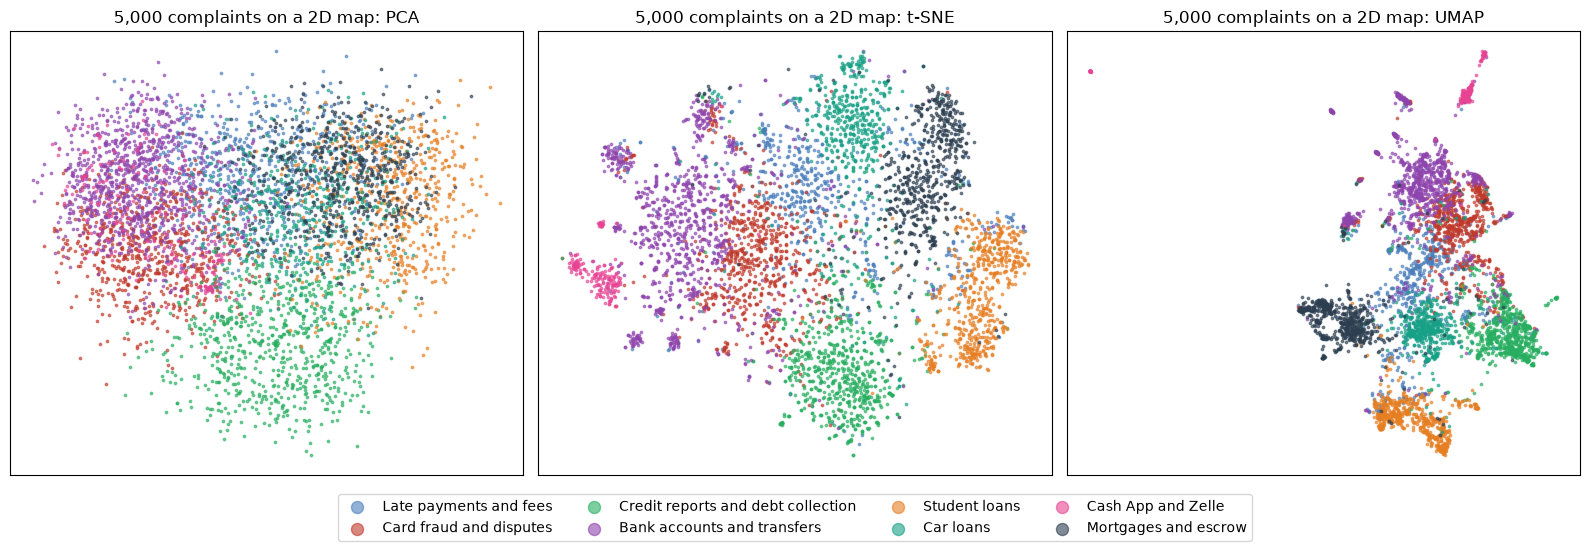

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
maps = [
    ("PCA", map_pca),
    ("t-SNE", map_tsne),
    ("UMAP", map_umap),
]
for ax, (method, coordinates) in zip(axes, maps):
    for cluster, name in CLUSTER_NAMES.items():
        in_cluster = (cluster_of == cluster).to_numpy()
        ax.scatter(
            coordinates[in_cluster, 0],
            coordinates[in_cluster, 1],
            s=3,
            alpha=0.6,
            color=CLUSTER_COLORS[cluster],
            label=name,
        )
    ax.set_title(f"5,000 complaints on a 2D map: {method}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    ncol=4,
    markerscale=5,
)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

`coordinates[in_cluster, 0]` takes the first column for the rows of one cluster. `fig.legend(*axes[0].get_legend_handles_labels(), ...)` builds one legend for the whole figure from the labels of the first chart, so it isn't repeated three times. The axes have no labels on purpose: on these maps the axes mean nothing, only who sits near whom.

- **PCA** shows one blob: the clusters sit in different corners but overlap at every border. Two straight axes keep only a small part of 384 dimensions.
- **t-SNE** and **UMAP** give each cluster its own region with much sharper borders, and a few small groups break off as islands, the Cash App cluster among them.
- On the UMAP map, one pink dot sits alone in the far corner: a few near-identical template texts, pushed far from everything. That one dot squeezes the rest of the map into a corner. The report in Demo 4 zooms past such dots.

**How to read t-SNE and UMAP without fooling yourself:**

1. **Sizes mean nothing.** A big island is not a big cluster; both methods stretch dense groups and squeeze sparse ones.
2. **Distances between islands may mean nothing.** Two islands far apart on the page may be close in the real space.
3. **Settings change the picture.** Run again with a different `n_neighbors` and the map rearranges (below).
4. **A map is for the eyes; the proof is the table.** Section 6's crosstab carries the evidence, the map goes on the report cover.

Two excellent interactive explanations: [How to Use t-SNE Effectively](https://distill.pub/2016/misread-tsne/) and [Understanding UMAP](https://pair-code.github.io/understanding-umap/).

The same data, UMAP with a small and a large `n_neighbors`:

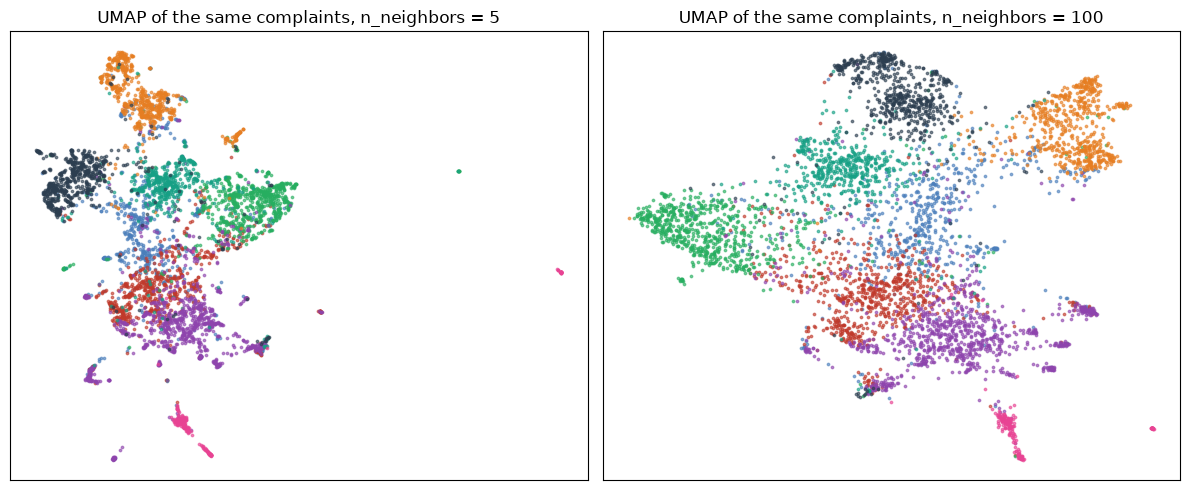

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, neighbours_kept in zip(axes, [5, 100]):
    coordinates = umap.UMAP(
        n_components=2,
        n_neighbors=neighbours_kept,
        random_state=42,
        n_jobs=1,
    ).fit_transform(embeddings)
    for cluster in CLUSTER_NAMES:
        in_cluster = (cluster_of == cluster).to_numpy()
        ax.scatter(
            coordinates[in_cluster, 0],
            coordinates[in_cluster, 1],
            s=3,
            alpha=0.6,
            color=CLUSTER_COLORS[cluster],
        )
    ax.set_title(f"UMAP of the same complaints, n_neighbors = {neighbours_kept}")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Same texts, same clusters, same colours, two different pictures. With 5 neighbours more small crumbs break off and drift away; with 100 the clusters are larger, smoother regions. Neither is "the truth".

## 8. The other order: compress first, then cluster

So far: encode → cluster in the full 384 dimensions → compress to 2 only to draw. A popular alternative:

1. encode;
2. **compress with UMAP to about 10 dimensions** (enough to keep the structure, few enough for distances to work well: point 8 of Demo 1's list);
3. **cluster with HDBSCAN** (Demo 1, section 7: groups are dense areas, no k, loners become noise);
4. compress to 2 dimensions to draw.

This is the recipe inside **BERTopic**, a popular library for finding topics in texts: an encoder (by default the same MiniLM), UMAP, HDBSCAN, and class-based TF-IDF to describe each topic. `min_dist=0.0` lets UMAP pack similar texts tightly, which helps the clustering step.

In [25]:
from sklearn.cluster import HDBSCAN

compressed = umap.UMAP(
    n_components=10,
    n_neighbors=15,
    min_dist=0.0,
    random_state=42,
    n_jobs=1,
).fit_transform(embeddings)

# copy=True leaves our table untouched (and silences a warning about a future default)
topic_labels = HDBSCAN(min_cluster_size=30, copy=True).fit(compressed).labels_
topic_of = pd.Series(topic_labels, index=complaint_texts.index, name="topic")

found_topics = topic_of[topic_of != -1].nunique()
print(
    f"HDBSCAN found {found_topics} topics\n"
    f"noise (in no topic): {(topic_of == -1).mean():.0%} of the complaints"
)

HDBSCAN found 24 topics
noise (in no topic): 29% of the complaints


In [26]:
topic_words = word_weights.groupby(topic_of).mean()
topic_sizes = topic_of.value_counts()
for topic in sorted(topic_sizes.index):
    if topic == -1:
        continue
    top_words = topic_words.loc[topic].sort_values(ascending=False).head(5)
    topic_size = topic_sizes[topic]
    print(f"topic {topic:>2} ({topic_size:>4} texts): {', '.join(top_words.index)}")

topic  0 (  37 texts): coinbase, account, wallet, funds, support
topic  1 ( 123 texts): cash, app, cashapp, account, money
topic  2 (  51 texts): unfair, cash, app, resolution, act
topic  3 (  99 texts): paypal, account, money, funds, email
topic  4 ( 127 texts): fargo, wells, account, bank, money
topic  5 (  39 texts): venmo, account, money, suspended, funds
topic  6 ( 613 texts): loans, mohela, loan, student, forbearance
topic  7 (  46 texts): student, privacy, breach, ferpa, information
topic  8 ( 606 texts): mortgage, escrow, loan, insurance, payment
topic  9 (  32 texts): credit, application, denied, denial, hard
topic 10 (  51 texts): late, payment, credit, payments, reporting
topic 11 ( 692 texts): debt, credit, report, collection, account
topic 12 (  75 texts): capital, account, credit, card, bank
topic 13 (  45 texts): overdraft, fees, navy, transactions, charged
topic 14 (  32 texts): bonus, promotion, account, opening, checking
topic 15 ( 248 texts): car, vehicle, loan, cred

`continue` skips the rest of the loop for that round, so the noise label `-1` is not printed.

A different algorithm, a different answer. HDBSCAN doesn't need k, and it finds many more groups, including small dense ones that k-means merged. Inside money transfers alone there are separate topics for Coinbase, Cash App, PayPal, Venmo and Western Union, and the Cash App template from section 4 gets a topic of its own. Outside them: a student-data breach, car title releases, bonuses for opening an account. It also refuses to place almost a third of the complaints, which k-means forced into some cluster.

Neither answer is "right". They answer different questions. k-means: *"split everything into eight piles"*. HDBSCAN: *"show me the tight groups and leave the rest"*. For a first overview of a pile of texts, the first is easier to report; for finding specific, actionable problems, the second is often better.

## 9. One month is not a trend

The texts were sampled from every month, **not in proportion to volume**: January 2025, the biggest month in the database, has 718 texts in our file, no more than a quiet month. Counting texts per month would only show our sampling. For real volumes, the second file holds the **full database counts**, per product and month.

In [27]:
monthly = pd.read_parquet(DATA / "complaints" / "monthly_counts.parquet")
monthly["product_short"] = monthly["product"].map(PRODUCT_SHORT)

monthly_by_product = monthly.pivot_table(
    index="month",
    columns="product_short",
    values="total_complaints",
)
monthly_by_product

product_short,Bank account,Car loan,Credit card,Debt collection,Money transfer,Mortgage,Student loan
month,,,,,,,
2024-06,2279.0,571.0,2568.0,5754.0,800.0,936.0,603.0
2024-07,2557.0,575.0,2629.0,5675.0,831.0,1073.0,562.0
2024-08,2631.0,655.0,2823.0,6132.0,918.0,1108.0,531.0
2024-09,2469.0,642.0,2796.0,5997.0,817.0,1060.0,799.0
2024-10,2715.0,673.0,2849.0,6820.0,931.0,1056.0,751.0
2024-11,2915.0,658.0,2689.0,5614.0,905.0,1005.0,484.0
2024-12,2818.0,726.0,2961.0,6323.0,1165.0,1065.0,762.0
2025-01,13838.0,1133.0,4091.0,8924.0,41858.0,1347.0,1227.0
2025-02,3451.0,827.0,3043.0,6742.0,4698.0,1023.0,1009.0


`pivot_table` turns the long table into a wide one: months as rows, products as columns. By default it averages the rows that land in one cell, which is why the counts print as `2279.0`; with one row per month and product, the average is just the count.

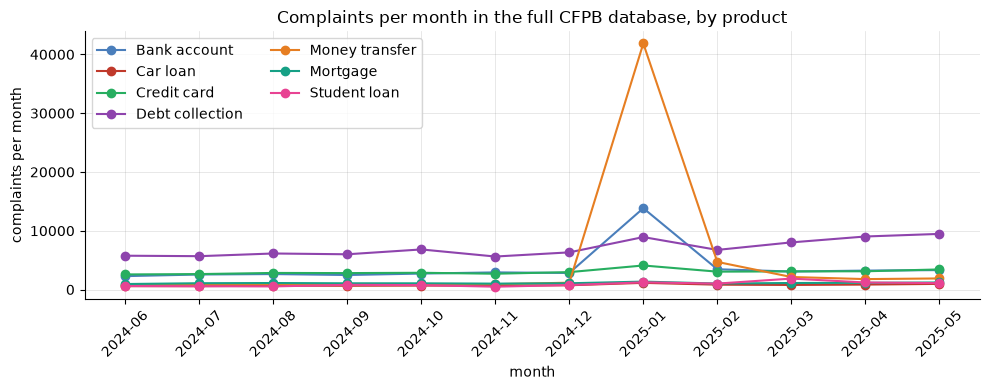

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
for column_number, product in enumerate(monthly_by_product.columns):
    ax.plot(
        monthly_by_product.index,
        monthly_by_product[product],
        marker="o",
        color=CLUSTER_COLORS[column_number],
        label=product,
    )
ax.set_title("Complaints per month in the full CFPB database, by product")
ax.set_xlabel("month")
ax.set_ylabel("complaints per month")
ax.legend(ncol=2)
ax.tick_params(axis="x", rotation=45)
make_ax_better(ax)
plt.tight_layout()
plt.show()

One spike dominates everything: **January 2025**. Money transfers jump from about a thousand complaints a month to over 40 thousand, bank accounts from about 3 thousand to almost 14 thousand. A month later, bank accounts are almost back to normal. Money transfers are not: about 4,700 in February, five times a usual month, then around 1,800 to 2,100 a month in spring, twice the 2024 level. On the chart this is hard to see, because one tall spike squeezes every other point towards zero. The table above shows it.

Now the question a manager asks: *"Which product grew the most this year?"* Compare the average month in 2025 with the average month in 2024, once with January and once without:

In [29]:
is_2025 = monthly_by_product.index >= "2025-01"
is_january = monthly_by_product.index == "2025-01"

average_2024 = monthly_by_product[~is_2025].mean()
growth_with_january = monthly_by_product[is_2025].mean() / average_2024 - 1
average_2025_no_january = monthly_by_product[is_2025 & ~is_january].mean()
growth_without_january = average_2025_no_january / average_2024 - 1

growth = pd.DataFrame({
    "with January": growth_with_january,
    "without January": growth_without_january,
})
(growth * 100).round(0).sort_values("with January", ascending=False)

,with January,without January
product_short,,
Money transfer,1051.0,188.0
Bank account,105.0,24.0
Student loan,99.0,101.0
Car loan,41.0,33.0
Debt collection,40.0,37.0
Credit card,21.0,15.0
Mortgage,12.0,7.0


`~` flips a True/False mask: `~is_2025` means "not 2025".

With January, money transfers "grew" by about +1,050%, more than ten times. Without that one month, they grew by about +190%: still the fastest, but a completely different story, and part of it is February's aftershock. Bank accounts drop from +105% to +24%. Student loans, on the other hand, roughly doubled with or without January: that growth is real. **One month can make the whole "trend"**. An analyst who reports +1,000% without looking at the line has reported an accident.

What happened in January 2025? The texts can't say: they were not sampled by volume. They do give hints: from January the most complained-about company in money transfers changes from PayPal to Block (Cash App), and in February template complaints appear that mention the regulator's lawsuit against Zelle, filed in December 2024. Finding out is a question for the business, not for a chart.

This is the same idea as noise in DBSCAN, in general words: **an anomaly is a point that doesn't look like the others**. With time series, a common approach is to describe each day or week by a profile (volumes by product, by hour, by channel), cluster the profiles, and flag the periods that fall into no cluster. January 2025 would be noise in any of them.

## 10. How to use clustering at work

A checklist, from tonight's three demos:

1. **Question and action.** What will you do differently for each group? No action, no clustering.
2. **The unit.** What is one point: a client, a day, a share, a text?
3. **Turn it into numbers.** Numbers: standardize. Texts: TF-IDF or an encoder. Time series: returns, or a profile per period.
4. **Too many columns?** Compress: PCA for straight structure and readable components; UMAP before clustering texts.
5. **Algorithm by the shape you expect.** Round, similar-sized groups: k-means. Odd shapes, noise, unknown number of groups: HDBSCAN (or DBSCAN). A tree, or nested groups: hierarchical. The [scikit-learn overview](https://scikit-learn.org/stable/modules/clustering.html#overview-of-clustering-methods) has the full table.
6. **Settings.** k: elbow and silhouette, then "can I name and use them". HDBSCAN: the smallest group worth acting on. DBSCAN: eps at the bend of the sorted k-distance line.
7. **Read the clusters.** Centers, typical words, the closest examples.
8. **Check stability.** Another `random_state`, another sample: are the groups still there?
9. **Name them, then check the names.** An assistant names at scale; you read the texts.
10. **Report.** A table and one picture; the conclusion in words, separately (session 3). The map is not the evidence.

## Try it yourself

1. Change `K` to 12. Which clusters split? Do the new pieces deserve their own names?
2. Cluster only the **mortgage** complaints. Make a True/False mask `is_mortgage` from `complaints.loc[complaint_texts.index, "product_short"] == "Mortgage"`, then use it twice: `complaint_texts[is_mortgage]` for the texts and `embeddings[is_mortgage.to_numpy()]` for their vectors. What problems inside mortgages appear?
3. Run section 8 with `min_cluster_size=80`. How many topics now, and what happened to the small ones?
4. 🤖 Ask an assistant to name all eight clusters from their typical words only, without texts. Compare with `CLUSTER_NAMES`. Where does it go wrong, and why?

In [30]:
# your turn

## Recap

- Text → numbers: **word counts** (a vector per text, a dimension per word), **TF-IDF** (rare words weigh more; BM25 is its search-engine cousin), an **encoder** (an embedding of 384 numbers where similar meaning = nearby, even without shared words).
- **Cosine similarity**: do two vectors point the same way? 1 = same, 0 = nothing in common.
- Check the space: nearest neighbours should tell the same story; near-identical twins are **templates**, a finding and a trap.
- Read clusters by **typical words** (average TF-IDF per cluster) and **texts closest to the center**; name them, let an assistant help, check yourself.
- The model found four official categories from raw text, and clusters that cut across them: complaints are about problems, not products.
- **PCA, t-SNE, UMAP** squeeze 384 dimensions onto a page. Sizes and gaps on t-SNE/UMAP maps mean little; settings change the picture; the table is the proof.
- **Compress, then cluster:** UMAP to ~10 dimensions + HDBSCAN (the BERTopic recipe) gives more, tighter topics and leaves loners out.
- **One month can make a "trend"**: look at the line before you report growth. An anomaly is a point unlike the others.

## ⚡ Extras — power tools, not required

**Clustering without an encoder.** k-means works on TF-IDF vectors too, with no neural network at all. It's how text clustering was done for years, and it is still a fine first try. Compare its clusters with the encoder's:

In [31]:
tfidf_kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
tfidf_kmeans.fit(complaint_word_matrix)
tfidf_cluster_of = pd.Series(tfidf_kmeans.labels_, index=complaint_texts.index)

(pd.crosstab(tfidf_cluster_of, cluster_name_of, normalize="index") * 100).round(0)

cluster,Bank accounts and transfers,Car loans,Card fraud and disputes,Cash App and Zelle,Credit reports and debt collection,Late payments and fees,Mortgages and escrow,Student loans
row_0,,,,,,,,
0,4.0,0.0,75.0,1.0,1.0,18.0,0.0,0.0
1,1.0,1.0,1.0,0.0,2.0,3.0,93.0,1.0
2,2.0,46.0,3.0,0.0,3.0,33.0,7.0,7.0
3,3.0,6.0,12.0,4.0,65.0,4.0,1.0,6.0
4,1.0,0.0,0.0,98.0,1.0,0.0,0.0,0.0
5,65.0,2.0,14.0,4.0,3.0,9.0,2.0,1.0
6,0.0,2.0,1.0,0.0,92.0,1.0,1.0,3.0
7,0.0,0.0,0.0,0.0,1.0,5.0,0.0,94.0


📎 Read more:

- [BERTopic](https://maartengr.github.io/BERTopic/algorithm/algorithm.html): the encoder → UMAP → HDBSCAN → class-based TF-IDF recipe, packaged.
- [sentence-transformers](https://www.sbert.net/): the library behind our encoder, and a list of other models (bigger, multilingual).
- [scikit-learn: manifold learning](https://scikit-learn.org/stable/modules/manifold.html): t-SNE and its relatives, with pictures.
- [Yandex's ML handbook, "Clustering"](https://contest.yandex.ru/tracks/ml/practical-topics/clustering) (in Russian).